# UJIAN TENGAH SEMESTER (UTS)
## Visualisasi Data Praktik Mandiri Berbasis Google Colab

* **Mata Kuliah:** Visualisasi Data (3 SKS)
* **Program Studi:** S1 Informatika - UIN K.H. Abdurrahman Wahid Pekalongan
* **Nama Mahasiswa:** Gathan Hilabi
* **NIM:** 60324059
* **Kelas:** Visualisasi Data (A)
* **Studi Kasus:** Gempa Bumi Dirasakan di Indonesia (Data BMKG hingga 13 Oktober 2026)

In [2]:
# Sel awal (wajib dijalankan pertama)
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io

uploaded = files.upload()

for fn in uploaded.keys():
  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')
  df_uploaded = pd.read_csv(io.BytesIO(uploaded[fn]))

df_uploaded.head()

User uploaded file "dataset_UTS_gempa_dirasakan_bmkg.csv" with length 598431 bytes


,id_gempa,waktu_utc,tahun,bulan,tanggal,lintang,bujur,magnitudo,kedalaman_km,lokasi,jenis_lokasi,dirasakan_di,catatan_kualitas
0,20221214195822,2022-12-14 12:58:22,2022,12,14,-7.50,106.76,3.9,24,Pusat gempa berada di laut 61 km Tenggara Kab....,Laut,II - III Sukabumi,NaN
1,20221214231338,2022-12-14 16:13:38,2022,12,14,-3.72,127.90,3.0,10,Pusat gempa berada di laut 31 km barat Ambon,Laut,II Hative Besar,NaN
2,20221215103109,2022-12-15 03:31:09,2022,12,15,2.88,127.50,5.0,13,Pusat gempa berada di laut 127 km BaratLaut Da...,Laut,II Morotai Selatan,NaN
3,20221215151321,2022-12-15 08:13:21,2022,12,15,-8.22,115.61,3.6,12,Pusat gempa berada di laut 17 km TimurLaut Kar...,Laut,"II Karangasem, II Tejakula",NaN
4,20221215164554,2022-12-15 09:45:54,2022,12,15,-8.23,115.57,4.1,10,Pusat gempa berada di laut 14 km Timurlaut Kar...,Laut,"II - III Karangasem, II Lombok Barat",NaN


---
## B1. Memuat dan Memahami Data (8 Poin)
**Ketentuan Soal:**
* Muat data ke DataFrame `df`. Tampilkan jumlah baris dan kolom (`shape`), 5 baris pertama, dan ringkasan `info()`.
* Pada sel Markdown jawab:
  1. Jumlah baris dan kolom;
  2. Kolom mana saja yang memiliki nilai kosong beserta jumlahnya;
  3. Arti nilai kosong pada kolom `catatan_kualitas`.

In [3]:
# Muat data ke DataFrame df
df = df_uploaded.copy()

# 1. Tampilkan jumlah baris dan kolom (shape)
print("=" * 60)
print(f"Bentuk data (shape): {df.shape[0]} baris x {df.shape[1]} kolom")
print("=" * 60)

# 2. Tampilkan 5 baris pertama
print("\n--- 5 Baris Pertama Data Gempa ---")
display(df.head())

# 3. Tampilkan ringkasan info()
print("\n--- Ringkasan Struktur Data (df.info()) ---")
df.info()

# 4. Tampilkan jumlah nilai kosong per kolom
print("\n--- Jumlah Nilai Kosong per Kolom ---")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

Bentuk data (shape): 3630 baris x 13 kolom

--- 5 Baris Pertama Data Gempa ---


,id_gempa,waktu_utc,tahun,bulan,tanggal,lintang,bujur,magnitudo,kedalaman_km,lokasi,jenis_lokasi,dirasakan_di,catatan_kualitas
0,20221214195822,2022-12-14 12:58:22,2022,12,14,-7.50,106.76,3.9,24,Pusat gempa berada di laut 61 km Tenggara Kab....,Laut,II - III Sukabumi,NaN
1,20221214231338,2022-12-14 16:13:38,2022,12,14,-3.72,127.90,3.0,10,Pusat gempa berada di laut 31 km barat Ambon,Laut,II Hative Besar,NaN
2,20221215103109,2022-12-15 03:31:09,2022,12,15,2.88,127.50,5.0,13,Pusat gempa berada di laut 127 km BaratLaut Da...,Laut,II Morotai Selatan,NaN
3,20221215151321,2022-12-15 08:13:21,2022,12,15,-8.22,115.61,3.6,12,Pusat gempa berada di laut 17 km TimurLaut Kar...,Laut,"II Karangasem, II Tejakula",NaN
4,20221215164554,2022-12-15 09:45:54,2022,12,15,-8.23,115.57,4.1,10,Pusat gempa berada di laut 14 km Timurlaut Kar...,Laut,"II - III Karangasem, II Lombok Barat",NaN



--- Ringkasan Struktur Data (df.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 3630 entries, 0 to 3629
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_gempa          3630 non-null   int64  
 1   waktu_utc         3630 non-null   str    
 2   tahun             3630 non-null   int64  
 3   bulan             3630 non-null   int64  
 4   tanggal           3630 non-null   int64  
 5   lintang           3630 non-null   float64
 6   bujur             3630 non-null   float64
 7   magnitudo         3630 non-null   float64
 8   kedalaman_km      3630 non-null   int64  
 9   lokasi            3630 non-null   str    
 10  jenis_lokasi      3613 non-null   str    
 11  dirasakan_di      3619 non-null   str    
 12  catatan_kualitas  11 non-null     str    
dtypes: float64(3), int64(5), str(5)
memory usage: 368.8 KB

--- Jumlah Nilai Kosong per Kolom ---
jenis_lokasi          17
dirasakan_di          11
catat

### Jawaban dan Analisis B1:
1. **Jumlah Baris dan Kolom:**
   * Dataset memiliki **3.630 baris** kejadian gempa dan **13 kolom** atribut (`shape = (3630, 13)`).
2. **Kolom yang Memiliki Nilai Kosong beserta Jumlahnya:**
   * `jenis_lokasi`: **17 baris** kosong (NaN)
   * `dirasakan_di`: **11 baris** kosong (NaN)
   * `catatan_kualitas`: **3.619 baris** kosong (NaN)
   *(Kolom-kolom lainnya terisi lengkap tanpa ada data yang kosong).*
3. **Arti Nilai Kosong pada Kolom `catatan_kualitas`:**
   * Nilai kosong pada kolom `catatan_kualitas` menandakan bahwa baris rekaman gempa tersebut **tidak memiliki catatan kendala sensor maupun anomali kualitas data** dari kurator BMKG (status datanya normal dan valid).
   * Nilai kosong ini **bukan data hilang atau data rusak yang harus dihapus**, melainkan penanda bahwa data tersebut memenuhi standar pemantauan operasional BMKG. Hanya ada 11 baris dalam dataset yang memiliki catatan anomali, yaitu berstatus `"FUTURE_EARTHQUAKE"`.

---
## B2. Pembersihan Data (14 Poin)
**Ketentuan Soal:**
Lakukan langkah berikut secara berurutan. Simpan hasil akhirnya pada DataFrame `df_bersih` dan gunakan untuk seluruh soal selanjutnya:
1. Buang baris yang pada kolom `catatan_kualitas` bernilai `"FUTURE_EARTHQUAKE"`. Berapa baris yang dibuang?
2. Jalankan `describe()` pada kolom `lintang` dan `bujur`. Temukan nilai yang mustahil untuk wilayah Indonesia (acuan: bujur wajar berada pada 90°–145° BT), buang barisnya, dan jelaskan alasan Anda.
3. Periksa duplikasi berdasarkan `id_gempa` dan laporkan hasilnya.
4. Isi nilai kosong pada `jenis_lokasi` dengan `"Tidak diketahui"`. Laporkan jumlah baris `df_bersih`.

In [4]:
# Langkah 1: Buang baris dengan catatan_kualitas == "FUTURE_EARTHQUAKE"
baris_awal = len(df)
baris_future = (df['catatan_kualitas'] == 'FUTURE_EARTHQUAKE').sum()
df_bersih = df[df['catatan_kualitas'] != 'FUTURE_EARTHQUAKE'].copy()
print(f"1. Baris berstatus 'FUTURE_EARTHQUAKE' yang dibuang : {baris_future} baris")
print(f"   Jumlah baris setelah langkah 1                  : {len(df_bersih)} baris")

# Langkah 2: Jalankan describe() pada kolom lintang dan bujur
print("\n2. Statistik Deskriptif Lintang dan Bujur:")
display(df_bersih[['lintang', 'bujur']].describe())

# Temukan nilai koordinat yang mustahil untuk wilayah Indonesia (acuan: 90° - 145° BT)
koordinat_mustahil = df_bersih[(df_bersih['bujur'] < 90) | (df_bersih['bujur'] > 145)]
print(f"\n   Ditemukan {len(koordinat_mustahil)} baris koordinat bujur di luar batas wilayah Indonesia:")
display(koordinat_mustahil[['id_gempa', 'waktu_utc', 'lintang', 'bujur', 'lokasi']])

# Buang baris yang memiliki nilai bujur mustahil
df_bersih = df_bersih[(df_bersih['bujur'] >= 90) & (df_bersih['bujur'] <= 145)].copy()
print(f"   Jumlah baris setelah membuang koordinat mustahil : {len(df_bersih)} baris")

# Langkah 3: Periksa duplikasi berdasarkan id_gempa
jumlah_duplikasi = df_bersih.duplicated(subset=['id_gempa']).sum()
print(f"\n3. Jumlah duplikasi berdasarkan 'id_gempa'          : {jumlah_duplikasi} baris (tidak ada duplikasi)")

# Langkah 4: Isi nilai kosong pada jenis_lokasi dengan 'Tidak diketahui'
kosong_sebelum = df_bersih['jenis_lokasi'].isnull().sum()
df_bersih['jenis_lokasi'] = df_bersih['jenis_lokasi'].fillna('Tidak diketahui')
kosong_setelah = df_bersih['jenis_lokasi'].isnull().sum()
print(f"\n4. Mengisi nilai kosong pada jenis_lokasi:")
print(f"   - Nilai kosong sebelum imputasi : {kosong_sebelum}")
print(f"   - Nilai kosong setelah imputasi : {kosong_setelah}")

# Laporan akhir ukuran df_bersih
print("\n" + "=" * 60)
print(f"LAPORAN AKHIR: DataFrame df_bersih memiliki {df_bersih.shape[0]} baris dan {df_bersih.shape[1]} kolom.")
print("=" * 60)

1. Baris berstatus 'FUTURE_EARTHQUAKE' yang dibuang : 11 baris
   Jumlah baris setelah langkah 1                  : 3619 baris

2. Statistik Deskriptif Lintang dan Bujur:


,lintang,bujur
count,3619.000000,3619.000000
mean,-3.611050,118.562783
std,3.932918,12.826945
min,-11.780000,1.390000
25%,-7.150000,107.600000
50%,-3.650000,120.550000
75%,-1.155000,126.465000
max,8.530000,143.070000



   Ditemukan 1 baris koordinat bujur di luar batas wilayah Indonesia:


,id_gempa,waktu_utc,lintang,bujur,lokasi
147,20230118223523,2023-01-18 15:35:23,-2.25,1.39,Pusat gempa berada di laut 78 km Baratlaut Jay...


   Jumlah baris setelah membuang koordinat mustahil : 3618 baris

3. Jumlah duplikasi berdasarkan 'id_gempa'          : 0 baris (tidak ada duplikasi)

4. Mengisi nilai kosong pada jenis_lokasi:
   - Nilai kosong sebelum imputasi : 17
   - Nilai kosong setelah imputasi : 0

LAPORAN AKHIR: DataFrame df_bersih memiliki 3618 baris dan 13 kolom.


### Jawaban dan Analisis B2:
1. **Pembersihan `FUTURE_EARTHQUAKE`:**
   * Ditemukan dan dibuang sebanyak **11 baris** yang bernilai `catatan_kualitas == "FUTURE_EARTHQUAKE"`. Baris-baris ini merupakan kesalahan penanggalan uji coba sistem dengan tanggal masa depan sehingga tidak valid untuk dianalisis. Data berkurang dari 3.630 menjadi 3.619 baris.
2. **Nilai Mustahil pada Lintang dan Bujur:**
   * Berdasarkan hasil `describe()`, nilai minimum bujur tercatat **1,39° BT** yang mustahil untuk wilayah Indonesia (rentang astronomis Indonesia berada pada 90°–145° BT).
   * Pada baris data dengan `id_gempa = 20230118223523`, teks lokasi menyebutkan pusat gempa berada di laut 78 km Barat Laut Jayapura dengan lintang $-2,25$ dan bujur $1,39$. Secara geografis Jayapura terletak di Papua pada bujur sekitar 140,39° BT, sehingga nilai 1,39 adalah salah ketik saat input data.
   * Baris ini dibuang (**1 baris dibuang**), sehingga jumlah data menjadi 3.618 baris.
3. **Pemeriksaan Duplikasi `id_gempa`:**
   * Hasil pemeriksaan duplikasi `id_gempa` bernilai **0**. Seluruh baris data memiliki nomor identitas unik.
4. **Imputasi `jenis_lokasi` dan Jumlah Baris Akhir:**
   * Sebanyak **17 baris** bernilai kosong pada kolom `jenis_lokasi` telah diisi dengan nilai string `"Tidak diketahui"`.
   * DataFrame `df_bersih` yang siap digunakan untuk seluruh analisis memiliki total **3.618 baris** dan **13 kolom**.

---
## B3. Statistik Deskriptif, Groupby, dan Outlier (20 Poin)
**Ketentuan Soal:**
1. Tulis fungsi `kategori_kedalaman(km)` dengan aturan: kurang dari 60 km = `"Dangkal"`; 60–300 km = `"Menengah"`; lebih dari 300 km = `"Dalam"`. Terapkan pada seluruh baris, simpan pada kolom `kategori_kedalaman`, dan tampilkan jumlah tiap kategori.
2. Tampilkan `describe()` untuk `magnitudo` dan `kedalaman_km`. Bandingkan mean dan median `kedalaman_km`, lalu jelaskan bentuk distribusinya.
3. Dengan `groupby`, hitung jumlah kejadian dan rata-rata magnitudo per tahun. Jelaskan mengapa tahun 2022 dan 2026 tidak dapat dibandingkan langsung dengan tahun lain.
4. Buat `pivot_table` jumlah kejadian dengan baris `jenis_lokasi` dan kolom `kategori_kedalaman`. Sebutkan sel dengan jumlah terbesar dan satu temuan menarik lainnya.
5. Terapkan metode IQR pada `magnitudo`: tampilkan Q1, Q3, batas atas, dan jumlah outlier. Apakah gempa Nagekeo (M7,0) termasuk outlier?

In [5]:
# 1. Fungsi kategori_kedalaman(km) dan penerapannya
def kategori_kedalaman(km):
    if km < 60:
        return 'Dangkal'
    elif km <= 300:
        return 'Menengah'
    else:
        return 'Dalam'

df_bersih['kategori_kedalaman'] = df_bersih['kedalaman_km'].apply(kategori_kedalaman)
print("1. Jumlah Tiap Kategori Kedalaman:")
display(df_bersih['kategori_kedalaman'].value_counts())

# 2. Statistik deskriptif magnitudo dan kedalaman_km
print("\n2. Statistik Deskriptif Magnitudo dan Kedalaman (km):")
display(df_bersih[['magnitudo', 'kedalaman_km']].describe())

mean_depth = df_bersih['kedalaman_km'].mean()
median_depth = df_bersih['kedalaman_km'].median()
print(f"   - Mean Kedalaman   : {mean_depth:.2f} km")
print(f"   - Median Kedalaman : {median_depth:.2f} km")

# 3. Groupby per tahun (Jumlah kejadian, rata-rata magnitudo, dan rentang waktu pencatatan)
print("\n3. Jumlah Kejadian dan Rata-rata Magnitudo per Tahun:")
rekap_tahunan = df_bersih.groupby('tahun').agg(
    jumlah_kejadian=('id_gempa', 'count'),
    rata_rata_magnitudo=('magnitudo', 'mean')
).reset_index()
display(rekap_tahunan)

print("\n   Bukti Rentang Waktu Pencatatan per Tahun (min dan max waktu_utc):")
rentang_waktu = df_bersih.groupby('tahun')['waktu_utc'].agg(['min', 'max'])
display(rentang_waktu)

# 4. Pivot table: jenis_lokasi vs kategori_kedalaman
print("\n4. Pivot Table Jumlah Kejadian (jenis_lokasi x kategori_kedalaman):")
tabel_pivot = df_bersih.pivot_table(
    index='jenis_lokasi',
    columns='kategori_kedalaman',
    values='id_gempa',
    aggfunc='count',
    fill_value=0
)[['Dangkal', 'Menengah', 'Dalam']]
display(tabel_pivot)

# 5. Metode IQR pada magnitudo
q1_mag = df_bersih['magnitudo'].quantile(0.25)
q3_mag = df_bersih['magnitudo'].quantile(0.75)
iqr_mag = q3_mag - q1_mag
batas_atas_mag = q3_mag + 1.5 * iqr_mag
outlier_mag = df_bersih[df_bersih['magnitudo'] > batas_atas_mag]

print("\n5. Analisis Outlier Magnitudo Menggunakan Metode IQR:")
print(f"   - Kuartil 1 (Q1) : {q1_mag:.2f}")
print(f"   - Kuartil 3 (Q3) : {q3_mag:.2f}")
print(f"   - Rentang IQR    : {iqr_mag:.2f}")
print(f"   - Batas Atas     : {batas_atas_mag:.2f}")
print(f"   - Jumlah Outlier : {len(outlier_mag)} kejadian")
print(f"   - Status Gempa Nagekeo (M7.0) : {'OUTLIER' if 7.0 > batas_atas_mag else 'BUKAN OUTLIER'} (karena 7.0 > {batas_atas_mag:.2f})")

1. Jumlah Tiap Kategori Kedalaman:


kategori_kedalaman
Dangkal     3366
Menengah     242
Dalam         10
Name: count, dtype: int64


2. Statistik Deskriptif Magnitudo dan Kedalaman (km):


,magnitudo,kedalaman_km
count,3618.000000,3618.000000
mean,3.969652,20.035379
std,1.034726,38.823789
min,1.400000,1.000000
25%,3.200000,6.000000
50%,4.000000,10.000000
75%,4.700000,17.000000
max,7.900000,636.000000


   - Mean Kedalaman   : 20.04 km
   - Median Kedalaman : 10.00 km

3. Jumlah Kejadian dan Rata-rata Magnitudo per Tahun:


...


   Bukti Rentang Waktu Pencatatan per Tahun (min dan max waktu_utc):


,min,max
tahun,,
2022,2022-12-14 12:58:22,2022-12-31 17:22:07
2023,2023-01-01 10:52:39,2023-12-31 15:15:10
2024,2024-01-01 03:22:46,2024-12-30 16:21:00
2025,2025-01-01 01:44:13,2025-12-31 06:28:08
2026,2026-01-01 06:02:00,2026-10-13 10:22:02



4. Pivot Table Jumlah Kejadian (jenis_lokasi x kategori_kedalaman):


kategori_kedalaman,Dangkal,Menengah,Dalam
jenis_lokasi,,,
Darat,1791,71,0
Laut,1560,169,10
Tidak diketahui,15,2,0



5. Analisis Outlier Magnitudo Menggunakan Metode IQR:
   - Kuartil 1 (Q1) : 3.20
   - Kuartil 3 (Q3) : 4.70
   - Rentang IQR    : 1.50
   - Batas Atas     : 6.95
   - Jumlah Outlier : 14 kejadian
   - Status Gempa Nagekeo (M7.0) : OUTLIER (karena 7.0 > 6.95)


### Jawaban dan Analisis B3:
1. **Jumlah Tiap Kategori Kedalaman:**
   * **Dangkal (< 60 km):** **3.366 kejadian** (93,03%)
   * **Menengah (60–300 km):** **242 kejadian** (6,69%)
   * **Dalam (> 300 km):** **10 kejadian** (0,28%)
   * Mayoritas besar gempa yang getarannya dirasakan oleh masyarakat di Indonesia merupakan gempa dangkal dekat permukaan bumi.
2. **Bentuk Distribusi Kedalaman (`kedalaman_km`):**
   * Nilai **Mean (20,04 km)** jauh lebih besar daripada **Median (10,00 km)**, dengan rentang nilai dari 1 hingga 636 km.
   * Bentuk distribusi kedalaman adalah **miring ke kanan (positively skewed)**. Sebagian besar kejadian berpusat sangat dangkal (median 10 km), sedangkan sebagian kecil gempa di zona subduksi dalam menarik nilai rata-rata ke atas. Oleh karena itu, median (10 km) jauh lebih realistis mewakili kedalaman tipikal.
3. **Perbandingan Tahunan (2022 dan 2026):**
   * Berdasarkan bukti tabel rentang waktu pencatatan, tahun 2022 dan 2026 **tidak dapat dibandingkan langsung secara adil dengan tahun 2023–2025** karena keduanya **bukan data satu tahun kalender penuh (12 bulan)**:
     * **Tahun 2022:** Hanya memuat data mulai **14 Desember 2022** (hanya sekitar setengah bulan) dengan 36 kejadian.
     * **Tahun 2026:** Hanya memuat data hingga **13 Oktober 2026** (sekitar 9,5 bulan) dengan 927 kejadian.
     * Sebaliknya, tahun 2023 (928 kejadian), 2024 (755 kejadian), dan 2025 (972 kejadian) mencakup rentang 12 bulan penuh. Angka 927 kejadian pada 2026 meskipun belum setahun penuh menandakan aktivitas seismik yang sangat intensif, terutama pascagempa Nagekeo.
4. **Temuan Pivot Table:**
   * **Sel dengan jumlah terbesar:** **Darat – Dangkal** dengan **1.791 kejadian** (disusul Laut – Dangkal sebanyak 1.560 kejadian).
   * **Temuan menarik lainnya:** Seluruh gempa berkategori **"Dalam" (> 300 km) terjadi di wilayah Laut (10 kejadian)**; tidak ada satupun gempa dalam yang tercatat di Darat (0 kejadian). Gempa menengah juga didominasi di Laut (169 kejadian vs 71 di darat), mencerminkan zona penunjaman lempeng samudra ke dalam mantel bumi di lepas pantai kepulauan Indonesia.
5. **Metode IQR pada Magnitudo:**
   * $Q1 = 3,20$, $Q3 = 4,70$, $IQR = 4,70 - 3,20 = 1,50$.
   * **Batas atas outlier:** $Q3 + (1,5 \times IQR) = 4,70 + (1,5 \times 1,50) = \mathbf{6,95}$.
   * **Jumlah Outlier:** Terdapat **14 kejadian** gempa dengan magnitudo di atas 6,95.
   * **Status Gempa Nagekeo (M7,0):** **Termasuk outlier**, karena nilai magnitudo gempa Nagekeo (7,0) berada di atas batas atas outlier (6,95).

---
## B4. Visualisasi (Matplotlib dan Seaborn) (26 Poin)
**Ketentuan Soal:**
1. **Bar chart Matplotlib (10 poin):**
   * Buat grafik batang jumlah kejadian per bulan pada tahun 2026 (Januari–Oktober).
   * Syarat: batang bulan Agustus berwarna berbeda; nilai angka tampil di atas setiap batang; ada judul, label sumbu, grid horizontal; satu anotasi yang menunjuk ke Agustus; garis tepi atas dan kanan disembunyikan.
2. **Tiga panel Seaborn (16 poin):**
   * Dalam satu figure berukuran 1 baris x 3 kolom, buat:
     - (i) Histogram magnitudo dengan KDE (bins = 25);
     - (ii) Boxplot magnitudo per `jenis_lokasi` dengan urutan `Darat`, `Laut`, `Tidak diketahui`;
     - (iii) Scatter plot bujur (sumbu x) terhadap lintang (sumbu y) dengan warna berdasarkan `kategori_kedalaman`.
   * Setiap panel wajib berjudul dan berlabel sumbu.
   * Gunakan `tight_layout()` dan simpan figure sebagai `uts_grafik.png` sebelum menampilkannya.

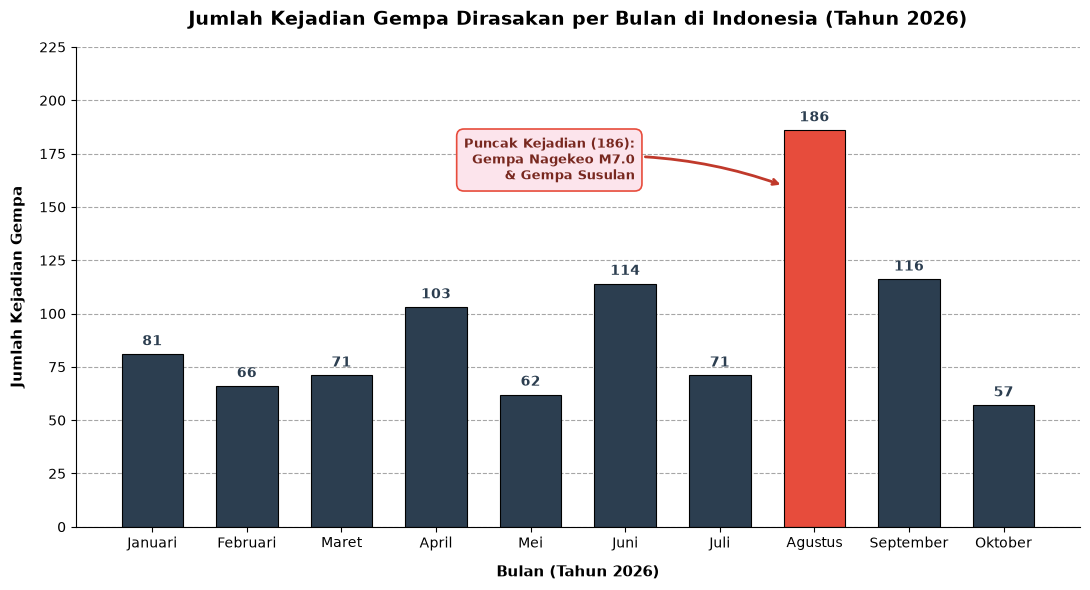

In [6]:
# B4.1: Bar Chart Matplotlib - Jumlah Kejadian per Bulan pada Tahun 2026
# Filter data tahun 2026
df_2026 = df_bersih[df_bersih['tahun'] == 2026]

# Hitung jumlah kejadian per bulan (Januari s.d. Oktober)
bulan_series = df_2026.groupby('bulan')['id_gempa'].count().reindex(range(1, 11), fill_value=0)
nama_bulan = ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni', 'Juli', 'Agustus', 'September', 'Oktober']

# Batang bulan Agustus (indeks bulan 8) diberi warna merah berbeda dari bulan lainnya (biru gelap)
warna_batang = ['#e74c3c' if b == 8 else '#2c3e50' for b in bulan_series.index]

# Membuat figure dan axes
fig, ax = plt.subplots(figsize=(11, 6))

# Plot bar chart
bars = ax.bar(nama_bulan, bulan_series.values, color=warna_batang, width=0.65, edgecolor='black', linewidth=0.8)

# Menampilkan nilai angka tepat di atas setiap batang
ax.bar_label(bars, padding=4, fontsize=10, fontweight='bold', color='#2c3e50')

# Judul dan label sumbu
ax.set_title('Jumlah Kejadian Gempa Dirasakan per Bulan di Indonesia (Tahun 2026)', fontsize=14, fontweight='bold', pad=16)
ax.set_xlabel('Bulan (Tahun 2026)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Jumlah Kejadian Gempa', fontsize=11, fontweight='bold', labelpad=10)

# Grid horizontal
ax.grid(axis='y', linestyle='--', alpha=0.7, color='gray')
ax.set_axisbelow(True)

# Sembunyikan garis tepi atas dan kanan
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Atur batas sumbu y agar proporsional dan lega
ax.set_ylim(0, 225)

# Anotasi yang menunjuk ke batang bulan Agustus secara rapi tanpa menutupi angka
ax.annotate(
    'Puncak Kejadian (186):\nGempa Nagekeo M7.0\n& Gempa Susulan',
    xy=(6.67, 160),        # Menunjuk ke sisi bahu kiri batang merah Agustus
    xytext=(5.1, 172),      # Kotak diletakkan di ruang kosong atas Juni-Juli
    ha='right',
    va='center',
    arrowprops=dict(
        arrowstyle='->',
        connectionstyle='arc3,rad=-0.12',
        color='#c0392b',
        lw=2
    ),
    fontsize=9.5,
    fontweight='bold',
    color='#78281f',
    bbox=dict(boxstyle='round,pad=0.55', facecolor='#fce4ec', edgecolor='#e74c3c', linewidth=1.2)
)

plt.tight_layout()
plt.show()

Figure berhasil disimpan ke file 'uts_grafik.png' sebelum ditampilkan.


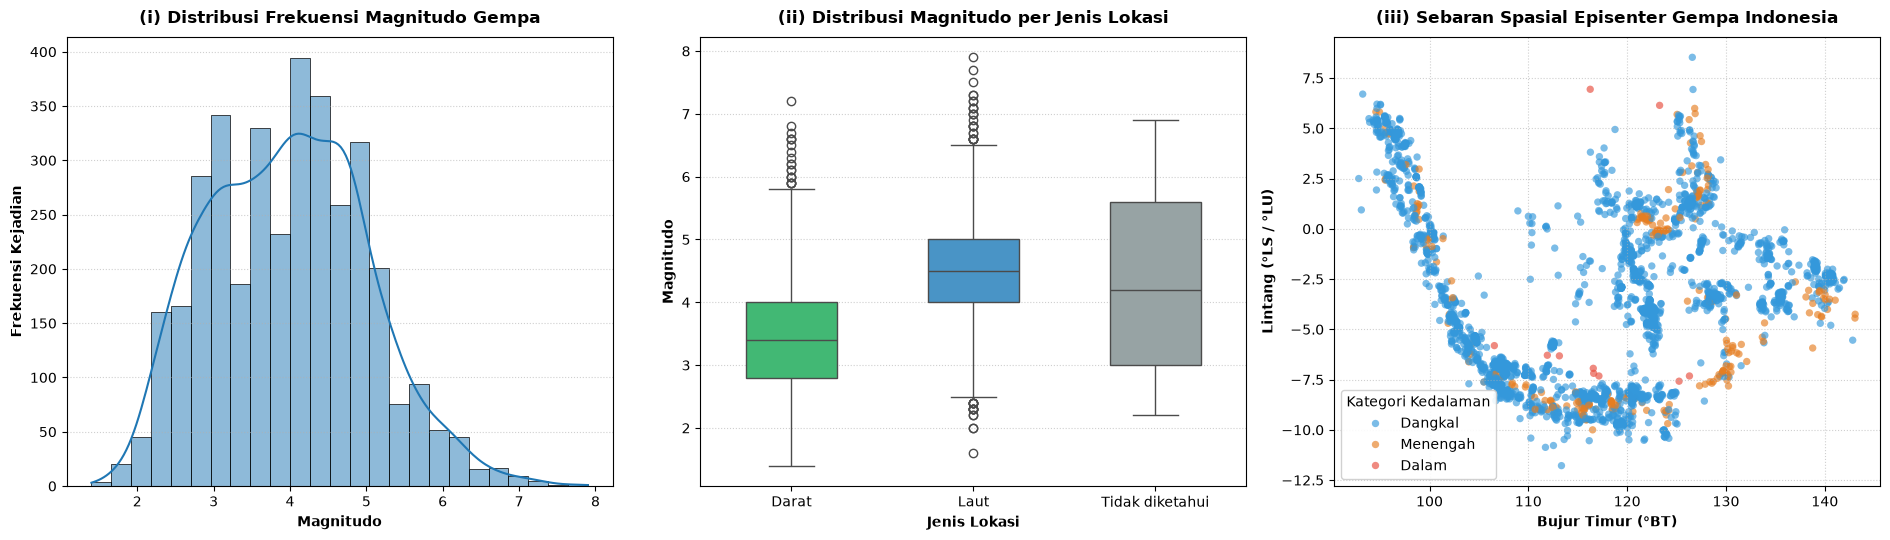


Bukti Nilai Median Magnitudo per Jenis Lokasi:


jenis_lokasi
Darat              3.4
Laut               4.5
Tidak diketahui    4.2
Name: magnitudo, dtype: float64

In [7]:
# B4.2: Tiga Panel Seaborn (1 baris x 3 kolom)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# (i) Panel 1: Histogram magnitudo dengan KDE (bins = 25)
sns.histplot(
    data=df_bersih,
    x='magnitudo',
    bins=25,
    kde=True,
    color='#1f77b4',
    edgecolor='black',
    linewidth=0.5,
    ax=axes[0]
)
axes[0].set_title('(i) Distribusi Frekuensi Magnitudo Gempa', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Magnitudo', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Frekuensi Kejadian', fontsize=10, fontweight='bold')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# (ii) Panel 2: Boxplot magnitudo per jenis_lokasi (urutan Darat, Laut, Tidak diketahui)
urutan_lokasi = ['Darat', 'Laut', 'Tidak diketahui']
palet_lokasi = {'Darat': '#2ecc71', 'Laut': '#3498db', 'Tidak diketahui': '#95a5a6'}

sns.boxplot(
    data=df_bersih,
    x='jenis_lokasi',
    y='magnitudo',
    order=urutan_lokasi,
    hue='jenis_lokasi',
    palette=palet_lokasi,
    legend=False,
    width=0.5,
    ax=axes[1]
)
axes[1].set_title('(ii) Distribusi Magnitudo per Jenis Lokasi', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Jenis Lokasi', fontsize=10, fontweight='bold')
axes[1].set_ylabel('Magnitudo', fontsize=10, fontweight='bold')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

# (iii) Panel 3: Scatter plot bujur vs lintang berdasarkan kategori_kedalaman
palet_kedalaman = {'Dangkal': '#3498db', 'Menengah': '#e67e22', 'Dalam': '#e74c3c'}
urutan_kedalaman = ['Dangkal', 'Menengah', 'Dalam']

sns.scatterplot(
    data=df_bersih,
    x='bujur',
    y='lintang',
    hue='kategori_kedalaman',
    hue_order=urutan_kedalaman,
    palette=palet_kedalaman,
    alpha=0.65,
    s=28,
    edgecolor='none',
    ax=axes[2]
)
axes[2].set_title('(iii) Sebaran Spasial Episenter Gempa Indonesia', fontsize=12, fontweight='bold', pad=10)
axes[2].set_xlabel('Bujur Timur (°BT)', fontsize=10, fontweight='bold')
axes[2].set_ylabel('Lintang (°LS / °LU)', fontsize=10, fontweight='bold')
axes[2].legend(title='Kategori Kedalaman', loc='lower left', framealpha=0.9)
axes[2].grid(True, linestyle=':', alpha=0.6)

# Gunakan tight_layout() dan simpan figure sebagai uts_grafik.png sebelum menampilkannya
plt.tight_layout()
fig.savefig('uts_grafik.png', dpi=300, bbox_inches='tight')
print("Figure berhasil disimpan ke file 'uts_grafik.png' sebelum ditampilkan.")
plt.show()

# Menampilkan bukti nilai median magnitudo per jenis lokasi
print("\nBukti Nilai Median Magnitudo per Jenis Lokasi:")
display(df_bersih.groupby('jenis_lokasi')['magnitudo'].median())

### Jawaban dan Analisis B4:
1. **Analisis Bar Chart Bulanan (2026):**
   * Grafik batang menunjukkan bahwa aktivitas gempa dirasakan di Indonesia pada tahun 2026 melonjak tajam pada bulan **Agustus 2026** dengan total **186 kejadian**, melampaui bulan-bulan lainnya yang memiliki rata-rata 60–110 kejadian.
   * Puncak aktivitas ini dipicu oleh gempa bumi utama Nagekeo M7,0 pada 15 Agustus 2026 yang diikuti rentetan gempa susulan berfrekuensi tinggi.
2. **Analisis Tiga Panel Seaborn:**
   * **Panel (i) Histogram & KDE Magnitudo:** Menunjukkan sebaran magnitudo terpusat di kisaran $M = 3,0 - 4,5$ dengan ekor distribusi miring ke kanan menuju gempa berkekuatan tinggi di atas $M = 6,5$.
   * **Panel (ii) Boxplot Magnitudo per Jenis Lokasi:** Terlihat perbedaan nyata di mana median magnitudo gempa Laut ($M = 4,5$) lebih tinggi daripada gempa Darat ($M = 3,4$). Gempa di darat dapat dirasakan pada kekuatan yang lebih kecil karena jarak pusat gempa sangat dekat dengan permukiman.
   * **Panel (iii) Scatter Plot Spasial:** Pola sebaran titik gempa dengan tepat merefleksikan batas pertemuan lempeng tektonik aktif Indonesia (Busur Sunda dari Sumatera hingga Nusa Tenggara, Busur Banda, Sulawesi, dan Papua). Gempa berkategori "Dalam" tampak terkonsentrasi di zona penunjaman laut dalam.

---
## B5. Korelasi dan Interpretasi Kritis (12 Poin)
**Ketentuan Soal:**
1. (3 poin) Buat heatmap korelasi untuk `magnitudo`, `kedalaman_km`, `lintang`, dan `bujur` (dengan angka). Sebutkan pasangan dengan korelasi terkuat dan nilainya.
2. (4 poin) Pada data Agustus 2026, hitung berapa kejadian yang berpusat pada lintang −9 hingga −7 dan bujur 120 hingga 123 (sekitar Flores), serta persentasenya terhadap seluruh kejadian Agustus 2026. Apa kesimpulan Anda?
3. (5 poin) Pada sel Markdown berjudul “Kesimpulan”, tulis empat pernyataan bernomor (masing-masing 1–2 kalimat, berangka):
   (1) Penjelasan lonjakan kejadian pada Agustus 2026;
   (2) Mengapa magnitudo gempa Nagekeo di data (7,0) berbeda dengan pemberitaan (7,7);
   (3) Perbandingan median magnitudo gempa darat dan laut beserta dugaan penjelasannya;
   (4) Satu keterbatasan data dan satu peringatan dalam menafsirkan korelasi.

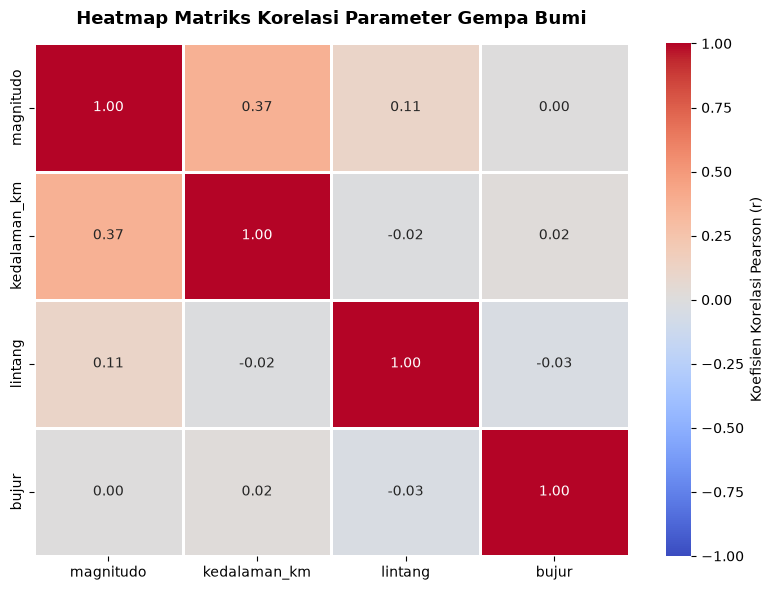

Matriks Korelasi Pearson:


,magnitudo,kedalaman_km,lintang,bujur
magnitudo,1.000000,0.371914,0.113686,0.004551
kedalaman_km,0.371914,1.000000,-0.015502,0.016930
lintang,0.113686,-0.015502,1.000000,-0.032776
bujur,0.004551,0.016930,-0.032776,1.000000



Pasangan dengan korelasi terkuat : magnitudo dan kedalaman_km
Nilai koefisien korelasi (r)     : 0.3719 (atau dibulatkan 0.37)


In [8]:
# B5.1: Heatmap korelasi magnitudo, kedalaman_km, lintang, dan bujur
kolom_fitur = ['magnitudo', 'kedalaman_km', 'lintang', 'bujur']
matriks_kor = df_bersih[kolom_fitur].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    matriks_kor,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.8,
    cbar_kws={'label': 'Koefisien Korelasi Pearson (r)'}
)
plt.title('Heatmap Matriks Korelasi Parameter Gempa Bumi', fontsize=13, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

# Menampilkan tabel matriks korelasi
print("Matriks Korelasi Pearson:")
display(matriks_kor)

# Mencari pasangan korelasi terkuat (di luar diagonal utama)
corr_unstack = matriks_kor.unstack()
corr_offdiag = corr_unstack[corr_unstack.index.get_level_values(0) != corr_unstack.index.get_level_values(1)]
pasangan_terkuat = corr_offdiag.abs().idxmax()
nilai_korelasi_terkuat = corr_offdiag[pasangan_terkuat]

print(f"\nPasangan dengan korelasi terkuat : {pasangan_terkuat[0]} dan {pasangan_terkuat[1]}")
print(f"Nilai koefisien korelasi (r)     : {nilai_korelasi_terkuat:.4f} (atau dibulatkan {nilai_korelasi_terkuat:.2f})")